# 04 - Classify the Full Raster (V2.0)

**What's different from V1:** the valid-pixel mask now checks for NaN directly (matching V2's NaN-nodata convention from preprocessing), and the output is written through `raster_io_v2.write_geotiff()` for consistency with the rest of the pipeline.

**Before running:** run `03_train_models_v2.ipynb` first.

**Output:** `outputs/classified_map.tif` -- open this in QGIS.

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path('..') / 'scripts'))

import config_v2 as config
import training_v2 as training
import classification_v2 as classification
import raster_io_v2 as rio


## Load the trained model chosen in config.FINAL_MODEL_FOR_PREDICTION

In [2]:
model_paths = {
    'random_forest': config.RF_MODEL_PATH,
    'svm': config.SVM_MODEL_PATH,
    'logistic_regression': config.LR_MODEL_PATH,
}

model_path = model_paths[config.FINAL_MODEL_FOR_PREDICTION]
model = training.load_model(model_path)
print(f'Loaded {config.FINAL_MODEL_FOR_PREDICTION} from {model_path}')


Loaded random_forest from D:\2.0\project_v2\models\random_forest.joblib


## Classify the whole AOI

In [3]:
classified_path = classification.classify_full_scene(model)


Loaded raster: 9 bands, 8738 rows, 5166 cols (45,140,508 pixels)
Predicting 45,112,704 valid pixels out of 45,140,508 total (27,804 are nodata)...
  predicted pixels 0-500,000 / 45,112,704
  predicted pixels 500,000-1,000,000 / 45,112,704
  predicted pixels 1,000,000-1,500,000 / 45,112,704
  predicted pixels 1,500,000-2,000,000 / 45,112,704
  predicted pixels 2,000,000-2,500,000 / 45,112,704
  predicted pixels 2,500,000-3,000,000 / 45,112,704
  predicted pixels 3,000,000-3,500,000 / 45,112,704
  predicted pixels 3,500,000-4,000,000 / 45,112,704
  predicted pixels 4,000,000-4,500,000 / 45,112,704
  predicted pixels 4,500,000-5,000,000 / 45,112,704
  predicted pixels 5,000,000-5,500,000 / 45,112,704
  predicted pixels 5,500,000-6,000,000 / 45,112,704
  predicted pixels 6,000,000-6,500,000 / 45,112,704
  predicted pixels 6,500,000-7,000,000 / 45,112,704
  predicted pixels 7,000,000-7,500,000 / 45,112,704
  predicted pixels 7,500,000-8,000,000 / 45,112,704
  predicted pixels 8,000,000-8,50

## Confirm the output is a proper, QGIS-readable GeoTIFF

In [4]:
info = rio.inspect_raster(config.CLASSIFIED_MAP_PATH)
for k, v in info.items():
    print(f'{k}: {v}')
assert info['driver'] == 'GTiff'
assert info['dtype'] == 'uint8'
print('\nOK -- ready to open in QGIS.')


path: D:\2.0\project_v2\outputs\classified_map.tif
driver: GTiff
dtype: uint8
count: 1
width: 5166
height: 8738
crs: EPSG:32643
resolution: (10.0, 10.0)
nodata: 0.0
bounds: (256950.0, 2109970.0, 308610.0, 2197350.0)

OK -- ready to open in QGIS.


## Preview the classified map with a legend

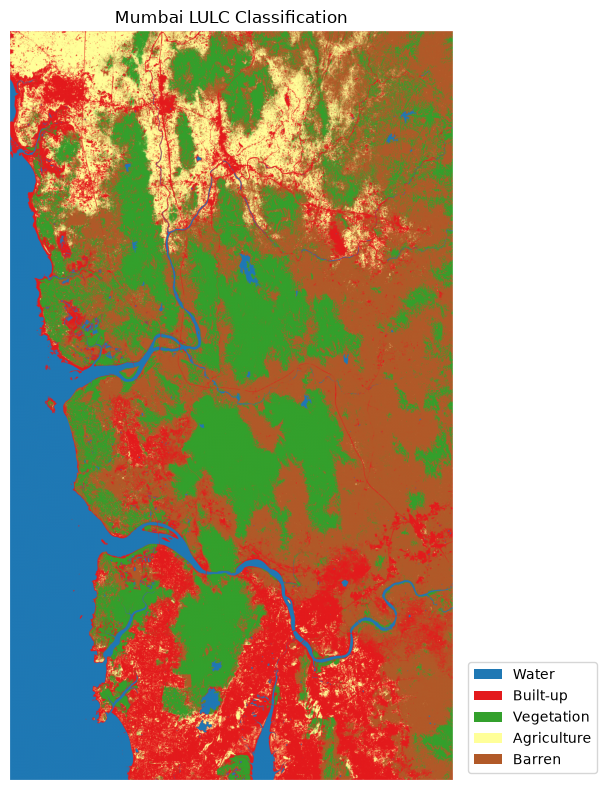

In [5]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

with rasterio.open(config.CLASSIFIED_MAP_PATH) as src:
    classified = src.read(1)

class_ids = sorted(config.CLASSES.keys())
class_names = [config.CLASSES[c] for c in class_ids]
colors = ['#1f78b4', '#e31a1c', '#33a02c', '#ffff99', '#b15928']

cmap = ListedColormap(colors[: len(class_ids)])
bounds = [c - 0.5 for c in class_ids] + [class_ids[-1] + 0.5]
norm = BoundaryNorm(bounds, cmap.N)

fig, ax = plt.subplots(figsize=(8, 8))
im = ax.imshow(np.ma.masked_equal(classified, 0), cmap=cmap, norm=norm)
ax.set_title('Mumbai LULC Classification')
ax.axis('off')

legend_elements = [Patch(facecolor=colors[i], label=class_names[i]) for i in range(len(class_ids))]
ax.legend(handles=legend_elements, loc='lower left', bbox_to_anchor=(1.02, 0))
plt.tight_layout()
plt.show()


## Done

`classified_map.tif` is saved. Open it in QGIS, symbolize values 1-5 as Water/Built-up/Vegetation/Agriculture/Barren (or whatever `report_actual_classes()` showed in notebook 02, if different), and add your legend, north arrow, scale bar, title, CRS, date and source.